# L4 - Numerical methods: Scipy

## Q5: Planetary orbits

We want to consider planetary orbits.  To do this, we need to solve Newton's second law together with Newton's law of gravity.  If we restrict ourselves to the x-y plane, then there are 4 quantities we need to solve for: $x$, $y$, $v_x$, and $v_y$.  These evolve according to:

\begin{align*}
\frac{dx}{dt} &= v_x \\
\frac{dy}{dt} &= v_y \\
\frac{dv_x}{dt} &= a_x = -\frac{GM_\star x}{r^3} \\
\frac{dv_y}{dt} &= a_y = -\frac{GM_\star y}{r^3}
\end{align*}

To integrate these forward in time, we need an initial condition for each quantity.  We'll setup our system such that the Sun is at the origin (that will be one focus), and the planet begins at perihelion and orbits counterclockwise. 

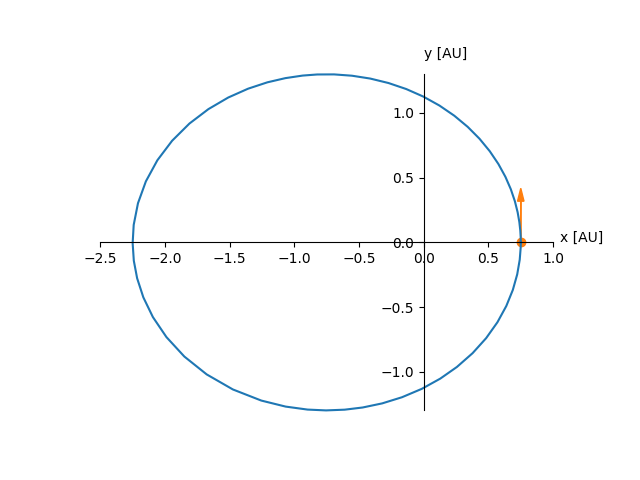

The distance of perihelion from the focus is:

$$r_p = a (1 - e)$$

where $a$ is the semi-major axis and $e$ is the eccentricity.  The perihelion velocity is all in the $y$ direction and is:

$$v_y = v_p = \sqrt{\frac{GM_\star}{a} \frac{1+e}{1-e}}$$

We'll work in units of AU, years, and solar masses, in which case, $GM_\star = 4\pi^2$ (for the Sun).  

Your initial conditions should be:

  * $x(t=0) = r_p$
  * $y(t=0) = 0$
  * $v_x(t=0) = 0$
  * $v_y(t=0) = v_p$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate

In [2]:
GM = 4*np.pi**2 # valid for the sun

# right hand side of the 4 equations, compute the derivatives
def rhs(t, EQ):
    x, y, vx, vy = EQ
    xdot = vx
    ydot = vy
    vxdot = -GM*x/(x**2 + y**2)**(3/2)
    vydot = -GM*y/(x**2 + y**2)**(3/2)

    return np.array([xdot, ydot, vxdot, vydot])


In [3]:
a = 1.0 # 1AU
e = 0.6 #random choise of e

# Initial settings 
rp = a*(1 - e)
vp = np.sqrt(GM/a * (1 + e)/(1 - e))
t0 = np.array([rp, 0, 0, vp])  # initial conditions

In [4]:
def ode_integrate(X0, dt, tmax):
    r = integrate.solve_ivp(rhs, (0.0, tmax), X0,
                            method="RK45", dense_output=True, rtol=1.e-7, atol=1.e-10)
    ts = np.arange(0.0, tmax, dt)
    Xs = r.sol(ts)
    return ts, Xs

ts, Ys = ode_integrate(t0, 0.001, 1.0) # tmax is 1 year

(-2.0, 2.0)

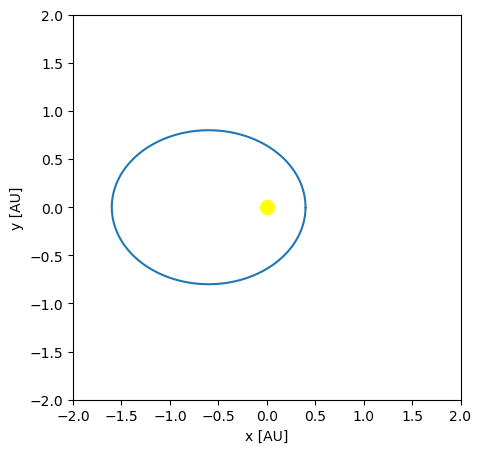

In [5]:
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111)

ax.plot(Ys[0,:], Ys[1,:])
ax.plot(0, 0, 'o', markersize=10, color='yellow') # sun

ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)

## Q8: FFT of the chaotic pendulum

In Q6 we looked at ODEs and the chaotic pendulum, and were interested in writing a method to integrate the pendulum in time.

Here we want to examine its behavior in frequency space.  The code below will integrate the chaotic pendulum, while requesting that the solution be stored at points spaced with a fixed dt, which makes it suitable for taking the FFT.

In [6]:
from functools import partial
from scipy.integrate import solve_ivp

def rhs(t, Y, q, omega_d, b):
    """ damped driven pendulum system derivatives.  Here, Y = (theta, omega) are
        the solution variables. """
    f = np.zeros_like(Y)
        
    f[0] = Y[1]
    f[1] = -q*Y[1] - np.sin(Y[0]) + b*np.cos(omega_d*t)

    return f

def restrict_theta(theta):
    """ convert theta to be restricted to lie between -pi and pi"""
    tnew = theta + np.pi
    tnew += -2.0*np.pi*np.floor(tnew/(2.0*np.pi))
    tnew -= np.pi
    return tnew

def int_pendulum(theta0, q, omega_d, b, tend, dt):
    """ integrate the pendulum and return solution with dt"""

    # points in time where we'll request the solution
    tpoints = np.arange(0.0, tend, dt)
    
    r = solve_ivp(partial(rhs, q=q, omega_d=omega_d, b=b),
                  [0.0, tend], [theta0, 0.0],
                  method='RK45', t_eval=tpoints)

    return r.t, r.y

The call below will give an undamped pendulum.  For a small amplitude, since we have $L = g$ in our pendulum, the period is simply $T = 2\pi$, and the frequency is $\nu_k = 1/(2\pi)$.  We plot things in terms of angular frequency, $\omega_k = 2\pi \nu_k$, so all the power will be at $\omega_k = 1$.

Your task is to complete the power spectrum routine below to calculate the FFT of theta and plot it.  Experiment with the damping and driving parameters to see the complexity of the pendulum in frequency space when it becomes chaotic.  For reference, here's a plot of the solution theta

Text(0, 0.5, '$\\theta$')

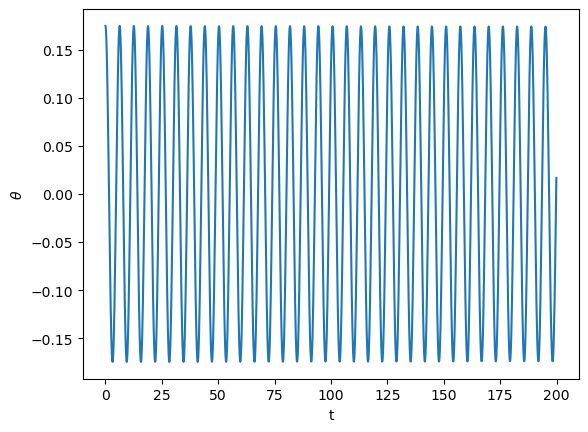

In [7]:
t, y = int_pendulum(np.radians(10), 0.0, 0.6666, 0.0, 200.0, 0.1)

#plot in time domain
plt.plot(t, restrict_theta(y[0,:]))
plt.xlabel("t")
plt.ylabel(r"$\theta$")


In [8]:
def power_spectrum(t, theta0):
    """ return the power spectrum of theta.  For the frequency
        component, return it in terms of omega """

    theta = restrict_theta(theta0) 
    npts = len(theta) #how many theta values (2000)
    theta_k = np.fft.rfft(theta) # real fourier transform
    power = np.abs(theta_k)**2 # the power is the square of theta_k abs value
    
    k = np.fft.rfftfreq(npts) # freq values for each theta_k
    dt = t[1] - t[0] # time between two theta values
    nu = k/dt # i want the number of cycles per unit of time
    omega = 2*np.pi * nu # omega is the angular frequency
    
    return omega, power

Text(0, 0.5, 'power')

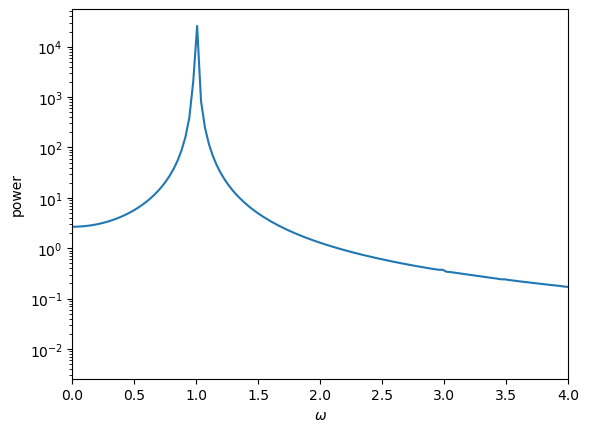

In [9]:
omega, power = power_spectrum(t, y[0, :])

#plot in frequency domain
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(omega, power)

ax.set_xlim(0, 4)
ax.set_yscale("log")
ax.set_xlabel(r"$\omega$")
ax.set_ylabel("power")

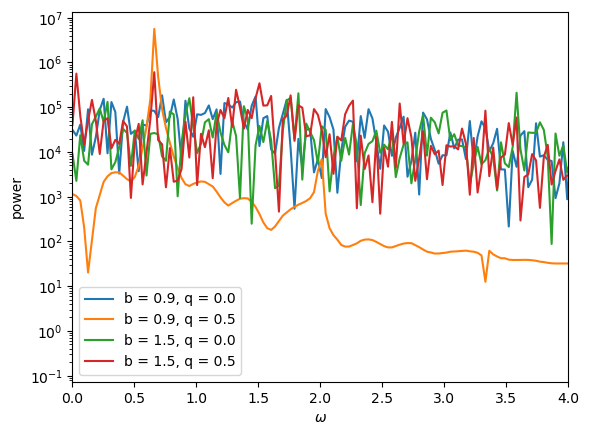

In [10]:
fig = plt.figure()
ax = fig.add_subplot(111)

# i test random values of b and q
for b in [0.9, 1.5]:
    for q in [0.0, 0.5]:
        t, y = int_pendulum(np.radians(10), q, 0.6666, b, 200.0, 0.1)
        omega, power = power_spectrum(t, y[0, :])
        ax.plot(omega, power, label="b = {}, q = {}".format(b, q))

ax.set_xlim(0, 4)
ax.set_yscale("log")
ax.set_xlabel(r"$\omega$")
ax.set_ylabel("power")
ax.legend()